# URLBERT Adversarially Trained (MODEL 2)
Retrain URLBERT with the same recipe as MODEL 1 on `train_original + train_adversarial`, then evaluate on `test_original` and `test_original + test_adversarial`, split into web.app / other / all urls.

In [1]:
%pip install -q -r ../../requirements.txt


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: /opt/pytorch/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from torch.utils.tensorboard import SummaryWriter
from transformers import BertConfig, BertForMaskedLM, BertTokenizerFast
from tqdm.auto import tqdm

os.environ["TOKENIZERS_PARALLELISM"] = "false"  # silence fork warning
sys.path.append("../../src")
from load_data import load_splits
from evaluate import evaluate, path_baseline, save_preds, adversarial_rows, group_evaluation, web_app

/opt/pytorch/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


# Setup
- `SMOKE = True` runs a quick check on 2000 rows (+ 200 adversarial rows) before the full run
- same hyperparameters as MODEL 1, only the training data changes

In [3]:
SMOKE = False

SEED = 42
BATCH_SIZE = 128  # same as MODEL 1
LR = 4e-5
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 1 if SMOKE else 5
EVAL_EVERY = 10 if SMOKE else 500  # steps between validations
PATIENCE = 3                        # evals without improvement before stopping
MIN_DELTA = 1e-4

TAG = "urlbert_model2_smoke" if SMOKE else "urlbert_model2"
URLBERT_DIR = "../../models/urlbert"
RESULTS = "../../results/urlbert"
CKPT = f"../../checkpoints/{TAG}.pt"
LOG = f"{RESULTS}/{TAG}_train_log.csv"
os.makedirs(RESULTS, exist_ok=True)
os.makedirs("../../checkpoints", exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
use_amp = device == "cuda"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.7.0+cu128


# Load Data
- `train_adversarial`: edited, non-duplicate rows of `urlbert_train_adversarial.csv` (label 0), appended to train after `MAX_LEN` is set
- `test_adversarial`: all attacked rows of `urlbert_test_adversarial_1.csv` (made against MODEL 1)
- val stays clean

In [4]:
splits = load_splits()
adv_train = adversarial_rows(pd.read_csv("../../data/adversarial/urlbert/urlbert_train_adversarial.csv"))
adv_test = pd.read_csv("../../data/adversarial/urlbert/urlbert_test_adversarial_1.csv")
if SMOKE:
    splits = {s: d.sample(2000 if s == "train" else 500, random_state=SEED) for s, d in splits.items()}
    adv_train, adv_test = adv_train.sample(200, random_state=SEED), adv_test.sample(200, random_state=SEED)

for s, d in {**splits, "train_adversarial": adv_train, "test_adversarial (attacked)": adv_test}.items():
    print(f"{s}: {len(d)} rows | phishing {(d.label == 0).mean():.1%} | web.app {web_app(d.URL).sum()}")

train: 185397 rows | phishing 41.8% | web.app 0
val: 23175 rows | phishing 41.8% | web.app 0
test: 23175 rows | phishing 41.8% | web.app 5605
train_adversarial: 13123 rows | phishing 100.0% | web.app 0
test_adversarial (attacked): 7729 rows | phishing 100.0% | web.app 5560


# Preprocess
- URLBERT's WordPiece tokenizer (vocab trained on URLs)

In [5]:
tokenizer = BertTokenizerFast(vocab_file=f"{URLBERT_DIR}/bert_tokenizer/vocab.txt", do_lower_case=True)
for u in splits["train"].URL[:3]:
    print(u, "->", tokenizer.tokenize(u))

southbankmosaics.com -> ['south', '##bank', '##mo', '##sa', '##ics', '.', 'com']
uni-mainz.de -> ['uni', '-', 'main', '##z', '.', 'de']
sfnmjournal.com -> ['sf', '##n', '##mj', '##ournal', '.', 'com']


In [6]:
#choose max token length (99th percentile of train_original, same as MODEL 1)
enc = tokenizer(splits["train"].URL.tolist())["input_ids"]
lengths = np.array([len(x) for x in enc])
unk_rate = np.mean(np.concatenate(enc) == tokenizer.unk_token_id)
MAX_LEN = min(int(np.percentile(lengths, 99)), 128)

print(f"token length: median {np.median(lengths):.0f}, p99 {np.percentile(lengths, 99):.0f}, max {lengths.max()}")
print(f"MAX_LEN = {MAX_LEN}, truncated = {(lengths > MAX_LEN).mean():.2%}, UNK rate = {unk_rate:.4%}")
assert unk_rate < 0.01, "tokenizer is not loading the vocab properly"

token length: median 9, p99 85, max 3220
MAX_LEN = 85, truncated = 0.99%, UNK rate = 0.0120%


In [7]:
#append train_adversarial (after MAX_LEN, so preprocessing matches MODEL 1)
splits["train"] = pd.concat([splits["train"], adv_train[["URL", "label"]]], ignore_index=True)
print(f"train: {len(splits['train'])} rows | phishing {(splits['train'].label == 0).mean():.1%}")

train: 198520 rows | phishing 45.7%


In [8]:
class URLDataset(Dataset):
    def __init__(self, df):
        self.ids = tokenizer(df.URL.tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]
        self.labels = df.label.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return torch.tensor(self.ids[i]), self.labels[i]


def collate(batch):
    # pad to longest in batch
    ids, labels = zip(*batch)
    ids = pad_sequence(ids, batch_first=True, padding_value=tokenizer.pad_token_id)
    return ids, (ids != tokenizer.pad_token_id).long(), torch.tensor(labels)


datasets = {s: URLDataset(d) for s, d in splits.items()}
train_loader = DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(datasets["val"], batch_size=256, collate_fn=collate)
test_loader = DataLoader(datasets["test"], batch_size=256, collate_fn=collate)

# Model
- retrained from pretrained URLBERT (not fine-tuned from MODEL 1)
- pretrained URLBERT encoder + linear layer on [CLS] (same head as URLBERT's phishing fine-tune)

In [9]:
config = BertConfig.from_json_file(f"{URLBERT_DIR}/bert_config/config.json")
config.vocab_size = 5000

mlm = BertForMaskedLM(config)
state = torch.load(f"{URLBERT_DIR}/urlBERT.pt", map_location="cpu", weights_only=True)
state.pop("bert.embeddings.position_ids", None)  # older checkpoints store this buffer
mlm.load_state_dict(state)  # strict: errors if weights don't match


class URLBERTClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.dropout = nn.Dropout(0.1)
        self.fc = nn.Linear(768, 2)

    def forward(self, input_ids, attention_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.fc(self.dropout(h))


model = URLBERTClassifier(mlm.bert).to(device)
del mlm, state
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

BertForMaskedLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly overwritten. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.


parameters: 89,292,290


# Training
- AdamW, linear warmup (6% of steps) then linear decay
- validate every `EVAL_EVERY` steps, early stopping on val loss, keep best checkpoint
- live curves: `tensorboard --logdir runs` (from repo root)

In [10]:
loss_fn = nn.CrossEntropyLoss()


@torch.no_grad()
def run_eval(loader):
    # returns mean loss and p_phish (label 0)
    model.eval()
    total, probs = 0.0, []
    for ids, mask, y in loader:
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(ids, mask).float()
        total += loss_fn(logits, y).item() * len(y)
        probs.append(torch.softmax(logits, -1)[:, 0].cpu())
    return total / len(loader.dataset), torch.cat(probs).numpy()


def predict(urls):
    ds = URLDataset(pd.DataFrame({"URL": list(urls), "label": 1}))
    return run_eval(DataLoader(ds, batch_size=256, collate_fn=collate))[1]

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = MAX_EPOCHS * len(train_loader)
warmup = int(0.06 * total_steps)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda s: s / max(1, warmup) if s < warmup else max(0.0, (total_steps - s) / max(1, total_steps - warmup))
)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
writer = SummaryWriter(f"../../runs/{TAG}")

log, running = [], []
best_val, bad, step, stopped = float("inf"), 0, 0, False

for epoch in range(1, MAX_EPOCHS + 1):
    for ids, mask, y in tqdm(train_loader, desc=f"epoch {epoch}"):
        model.train()
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            loss = loss_fn(model(ids, mask), y)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        step += 1
        running.append(loss.item())
        writer.add_scalar("loss/train_step", running[-1], step)

        if step % EVAL_EVERY == 0:
            val_loss, p_val = run_eval(val_loader)
            m = evaluate(datasets["val"].labels, p_val)
            improved = val_loss < best_val - MIN_DELTA
            if improved:
                best_val, bad = val_loss, 0
                torch.save(model.state_dict(), CKPT)
            else:
                bad += 1

            row = {"step": step, "epoch": epoch, "train_loss": np.mean(running), "val_loss": val_loss,
                   "val_acc": m["accuracy"], "val_recall": m["recall"], "val_f1": m["f1"],
                   "lr": scheduler.get_last_lr()[0], "best": improved}
            log.append(row)
            running = []
            pd.DataFrame(log).to_csv(LOG, index=False)

            writer.add_scalars("loss", {"train": row["train_loss"], "val": val_loss}, step)
            writer.add_scalar("val/f1", m["f1"], step)
            writer.add_scalar("val/recall", m["recall"], step)
            writer.add_scalar("lr", row["lr"], step)
            print(f"step {step} | train {row['train_loss']:.4f} | val {val_loss:.4f} | f1 {m['f1']:.4f}" + (" | best" if improved else ""))

            if bad >= PATIENCE:
                print(f"early stopping: val loss did not improve for {PATIENCE} evals")
                stopped = True
                break
    if stopped:
        break

writer.close()
if device == "cuda":
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB "
          f"of {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

epoch 1:   0%|          | 0/1551 [00:00<?, ?it/s]

step 500 | train 0.3849 | val 0.3429 | f1 0.8539 | best
step 1000 | train 0.2888 | val 0.2770 | f1 0.8597 | best
step 1500 | train 0.2745 | val 0.2701 | f1 0.8625 | best


epoch 2:   0%|          | 0/1551 [00:00<?, ?it/s]

step 2000 | train 0.2622 | val 0.2693 | f1 0.8628 | best
step 2500 | train 0.2579 | val 0.2673 | f1 0.8675 | best
step 3000 | train 0.2510 | val 0.2707 | f1 0.8697


epoch 3:   0%|          | 0/1551 [00:00<?, ?it/s]

step 3500 | train 0.2470 | val 0.2663 | f1 0.8619 | best
step 4000 | train 0.2426 | val 0.2629 | f1 0.8703 | best
step 4500 | train 0.2403 | val 0.2595 | f1 0.8703 | best


epoch 4:   0%|          | 0/1551 [00:00<?, ?it/s]

step 5000 | train 0.2371 | val 0.2764 | f1 0.8718
step 5500 | train 0.2302 | val 0.2631 | f1 0.8707
step 6000 | train 0.2313 | val 0.2569 | f1 0.8727 | best


epoch 5:   0%|          | 0/1551 [00:00<?, ?it/s]

step 6500 | train 0.2273 | val 0.2708 | f1 0.8720
step 7000 | train 0.2244 | val 0.2578 | f1 0.8728
step 7500 | train 0.2214 | val 0.2588 | f1 0.8725
early stopping: val loss did not improve for 3 evals
peak GPU memory: 6.1 GB of 15.6 GB


## Loss Curve

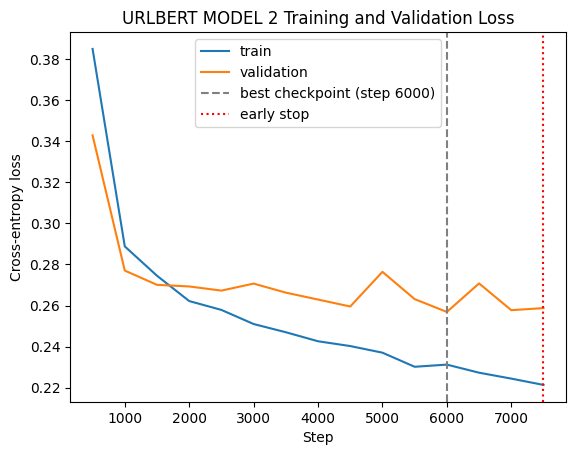

,step,epoch,train_loss,val_loss,val_acc,val_recall,val_f1,lr,best
10,5500,4,0.230201,0.263140,0.900496,0.801011,0.870711,0.000012,False
11,6000,4,0.231262,0.256893,0.900841,0.812668,0.872715,0.000010,True
12,6500,5,0.227317,0.270784,0.901446,0.802765,0.872030,0.000007,False
13,7000,5,0.224442,0.257757,0.903128,0.794203,0.872754,0.000004,False
14,7500,5,0.221369,0.258765,0.901446,0.806478,0.872545,0.000001,False


In [12]:
log_df = pd.read_csv(LOG)
best = log_df.loc[log_df.val_loss.idxmin()]

plt.plot(log_df.step, log_df.train_loss, label="train")
plt.plot(log_df.step, log_df.val_loss, label="validation")
plt.axvline(best.step, ls="--", c="grey", label=f"best checkpoint (step {int(best.step)})")
if stopped:
    plt.axvline(log_df.step.iloc[-1], ls=":", c="red", label="early stop")
plt.xlabel("Step")
plt.ylabel("Cross-entropy loss")
plt.title("URLBERT MODEL 2 Training and Validation Loss")
plt.legend()
plt.savefig(f"{RESULTS}/{TAG}_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

display(log_df.tail())

# Evaluate MODEL 2
## test_original
- best checkpoint, compared against the path reference rule (phishing if URL has a path)

In [13]:
model.load_state_dict(torch.load(CKPT, map_location=device, weights_only=True))
test_loss, p_test = run_eval(test_loader)
test = splits["test"]

test_metrics = evaluate(test.label, p_test)
save_preds(f"{RESULTS}/{TAG}_test_original.csv", test.URL, test.label, p_test)
with open(f"{RESULTS}/{TAG}_test_original.json", "w") as f:
    json.dump(test_metrics, f, indent=1)

comparison = pd.DataFrame({
    "MODEL 2": test_metrics,
    "path rule": evaluate(test.label, path_baseline(test.URL)),
}).drop("confusion_matrix").T
display(comparison.astype(float).round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc
MODEL 2,0.9024,0.9386,0.8202,0.8754,0.9429,0.9466
path rule,0.6210,1.0000,0.0939,0.1716,0.5469,0.4729


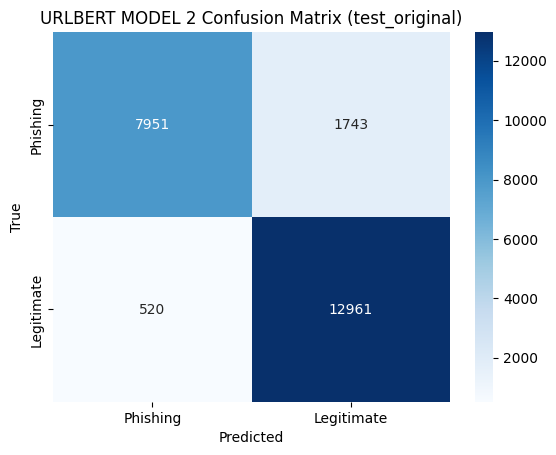

In [14]:
sns.heatmap(test_metrics["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
            xticklabels=["Phishing", "Legitimate"], yticklabels=["Phishing", "Legitimate"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("URLBERT MODEL 2 Confusion Matrix (test_original)")
plt.show()

## test_original + test_adversarial
- MODEL 2 scores both the original and the attacked urls
- `test_adversarial` was made against MODEL 1, so this measures MODEL 1's attacks transferred to MODEL 2 (not a white-box attack on MODEL 2)

In [15]:
test = splits["test"]
p_adv_clean, p_adv = predict(adv_test.orig_URL), predict(adv_test.URL)
m2 = group_evaluation(test, p_test, adv_test, p_adv_clean, p_adv).assign(model="MODEL 2")

edited = adversarial_rows(adv_test.assign(p_adv=p_adv))
save_preds(f"{RESULTS}/{TAG}_test_adversarial.csv", pd.concat([test.URL, edited.URL]),
           pd.concat([test.label, edited.label]), np.concatenate([p_test, edited.p_adv]))
row = m2[(m2.group == "all") & (m2.test_set == "test_original + test_adversarial")].iloc[0]
with open(f"{RESULTS}/{TAG}_test_adversarial.json", "w") as f:
    json.dump(row.drop(["group", "test_set", "model"]).to_dict(), f, indent=1)
print({k: round(float(v), 4) for k, v in row.items() if isinstance(v, float)})

{'accuracy': 0.9217, 'precision': 0.9642, 'recall': 0.8877, 'f1': 0.9244, 'roc_auc': 0.9642, 'pr_auc': 0.9766, 'attack_success_rate': 0.0038, 'n_attempts': 7718.0, 'confidence_reduction': 0.0173, 'adversarial_recall': 0.9954, 'robust_recall': 0.8172, 'delta_accuracy': 0.0193, 'delta_recall': 0.0675, 'delta_f1': 0.0489}


# Final Evaluation by URL Group
- web.app urls are only in test (all phishing, 58% of test phishing), so `all` is dominated by web.app: compare models within `other`
- web.app has no legitimate urls, so only recall-type metrics are reported there
- `robust_recall`: share of all phishing urls in the group still detected after the attack (same base for every model)
- MODEL 1 scores come from `results/urlbert_test_original.csv` and `data/urlbert_test_adversarial_1.csv` (no rerun)

In [16]:
ref = pd.read_csv(f"{RESULTS}/urlbert_test_original.csv")
p1_test = test.URL.map(dict(zip(ref.URL, ref.p_phish))).values
m1 = group_evaluation(test, p1_test, adv_test, adv_test.p_clean, adv_test.p_adv).assign(model="MODEL 1")

if not SMOKE:  # MODEL 1 'all' rows reproduce the saved overall metrics
    for ts, f in [("test_original", "urlbert_test_original"), ("test_original + test_adversarial", "urlbert_test_adversarial")]:
        with open(f"{RESULTS}/{f}.json") as fh:
            saved = json.load(fh)
        r = m1[(m1.group == "all") & (m1.test_set == ts)].iloc[0]
        assert all(np.isclose(r[k], saved[k]) for k in ["accuracy", "recall", "f1"]), ts

final = pd.concat([m1, m2], ignore_index=True)
final = final[["model", "group", "test_set"] + [c for c in final.columns if c not in ("model", "group", "test_set")]]
final.to_csv(f"{RESULTS}/urlbert_final_evaluation{'_smoke' if SMOKE else ''}.csv", index=False)
display(final.drop(columns="confusion_matrix").round(4))

,model,group,test_set,accuracy,precision,recall,f1,roc_auc,pr_auc,attack_success_rate,n_attempts,confidence_reduction,adversarial_recall,robust_recall,delta_accuracy,delta_recall,delta_f1
0,MODEL 1,all,test_original,0.9026,0.9635,0.7973,0.8725,0.9424,0.9457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MODEL 1,all,test_original + test_adversarial,0.8186,0.9735,0.6822,0.8022,0.9232,0.9483,0.4099,7729.0,0.3257,0.4986,0.4705,-0.0839,-0.1151,-0.0703
2,MODEL 1,web.app,test_original,NaN,NaN,0.9920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MODEL 1,web.app,test_original + test_adversarial,NaN,NaN,0.7298,NaN,NaN,NaN,0.5270,5560.0,0.4178,0.4336,0.4692,NaN,-0.2621,NaN
4,MODEL 1,other,test_original,0.8740,0.8810,0.5304,0.6622,0.8654,0.7736,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,MODEL 1,other,test_original + test_adversarial,0.8688,0.9123,0.5856,0.7133,0.8830,0.8290,0.1097,2169.0,0.0895,0.7871,0.4722,-0.0052,0.0551,0.0511
6,MODEL 2,all,test_original,0.9024,0.9386,0.8202,0.8754,0.9429,0.9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,MODEL 2,all,test_original + test_adversarial,0.9217,0.9642,0.8877,0.9244,0.9642,0.9766,0.0038,7718.0,0.0173,0.9954,0.8172,0.0193,0.0675,0.0489
8,MODEL 2,web.app,test_original,NaN,NaN,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,MODEL 2,web.app,test_original + test_adversarial,NaN,NaN,0.9984,NaN,NaN,NaN,0.0034,5560.0,0.0228,0.9966,0.9966,NaN,-0.0016,NaN


In [17]:
#MODEL 1 vs MODEL 2 per group
display(final.pivot_table(index=["group", "test_set"], columns="model", sort=False,
                          values=["recall", "f1", "robust_recall", "attack_success_rate", "delta_recall"]).round(4))

recall              f1          \
model                                    MODEL 1 MODEL 2 MODEL 1 MODEL 2   
group   test_set                                                           
all     test_original                     0.7973  0.8202  0.8725  0.8754   
        test_original + test_adversarial  0.6822  0.8877  0.8022  0.9244   
web.app test_original                     0.9920  1.0000     NaN     NaN   
        test_original + test_adversarial  0.7298  0.9984     NaN     NaN   
other   test_original                     0.5304  0.5737  0.6622  0.6746   
        test_original + test_adversarial  0.5856  0.6631  0.7133  0.7523   

                                         robust_recall          \
model                                          MODEL 1 MODEL 2   
group   test_set                                                 
all     test_original                              NaN     NaN   
        test_original + test_adversarial        0.4705  0.8172   
web.app test_original                              NaN     NaN   
        test_original + test_adversarial        0.4692  0.9966   
other   test_original                              NaN     NaN   
        test_original + test_adversarial        0.4722  0.5713   

                                         attack_success_rate          \
model                                                MODEL 1 MODEL 2   
group   test_set                                                       
all     test_original                                    NaN     NaN   
        test_original + test_adversarial              0.4099  0.0038   
web.app test_original                                    NaN     NaN   
        test_original + test_adversarial              0.5270  0.0034   
other   test_original                                    NaN     NaN   
        test_original + test_adversarial              0.1097  0.0046   

                                         delta_recall          
model                                         MODEL 1 MODEL 2  
group   test_set                                               
all     test_original                             NaN     NaN  
        test_original + test_adversarial      -0.1151  0.0675  
web.app test_original                             NaN     NaN  
        test_original + test_adversarial      -0.2621 -0.0016  
other   test_original                             NaN     NaN  
        test_original + test_adversarial       0.0551  0.0894

In [18]:
#other vs web.app per model
display(final.pivot_table(index=["model", "test_set"], columns="group",
                          values=["recall", "robust_recall", "attack_success_rate"]).round(4))

attack_success_rate                  \
group                                                    all   other web.app   
model   test_set                                                               
MODEL 1 test_original                                    NaN     NaN     NaN   
        test_original + test_adversarial              0.4099  0.1097  0.5270   
MODEL 2 test_original                                    NaN     NaN     NaN   
        test_original + test_adversarial              0.0038  0.0046  0.0034   

                                          recall                  \
group                                        all   other web.app   
model   test_set                                                   
MODEL 1 test_original                     0.7973  0.5304  0.9920   
        test_original + test_adversarial  0.6822  0.5856  0.7298   
MODEL 2 test_original                     0.8202  0.5737  1.0000   
        test_original + test_adversarial  0.8877  0.6631  0.9984   

                                         robust_recall                  
group                                              all   other web.app  
model   test_set                                                        
MODEL 1 test_original                              NaN     NaN     NaN  
        test_original + test_adversarial        0.4705  0.4722  0.4692  
MODEL 2 test_original                              NaN     NaN     NaN  
        test_original + test_adversarial        0.8172  0.5713  0.9966